# Apache SpamAssassin Spam Classification - Model Pipeline

Introductory TLDR goes here

## 1. Imports and Loading Packages

In [1]:
from pathlib import Path
import random

from utils import create_train_test_split, clean_emails, evaluate_model, plot_confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.base import clone


seed = 42

## 2. Train Test Split

Since the train test split has already been made, we will skip this step

## 3. Building Data Pipeline

This involves feature engineering, and model building.

For feature engineering, we will choose to either remove the headers altogether or selectively mask the headers. Furthermore, we will also mask the URLs, numbers, etc.
- remove stop words - good for tf-idf

For model building we will use a list of models that is yet to be decided.

In [2]:
DATASPLIT_DIR = Path('./data_split')
RAW_DATA_DIR = Path('./raw_data')

X_train, y_train, X_test, y_test = create_train_test_split(raw_data_dir=RAW_DATA_DIR, data_split_dir=DATASPLIT_DIR, seed=seed)
len(X_train), len(X_test), len(y_train), len(y_test)

(7330, 1835, 7330, 1835)

In [3]:
X_train = clean_emails(emails = X_train, remove_headers=True)

## 4. Feature Engineering

Because the models cannot handle the text data, we will have to convert them into a matrix.

In [4]:
vectorizer = TfidfVectorizer(input='content', lowercase=True, stop_words='english', encoding='latin-1', max_features=10000)

## 4. Model Building

In [5]:
pipe = Pipeline([
    ("vectorizer", vectorizer),
    ("classifier", 'passthrough') # placeholder
])

### Model 1 - Logistic Regression

Logistic regression is a very good linear classification baseline. ```class_weight = 'balanced'``` tries to correct the class imbalance.

Evaluation Metrics for Logistic Regression:
accuracy  : 0.8866
precision : 0.9625
recall    : 0.5887
f1        : 0.7306
roc_auc   : 0.9866


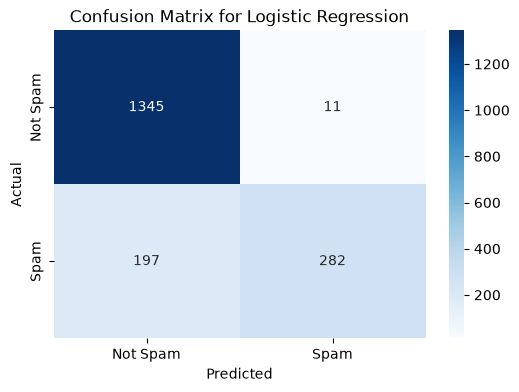

In [8]:
model_name = 'Logistic Regression'
lr = LogisticRegression(max_iter=2000, random_state=seed, class_weight='balanced')
lr_pipe = lr_pipe = clone(pipe).set_params(
    classifier=LogisticRegression()
)

lr_pipe.fit(X_train, y_train)
pred_lr = lr_pipe.predict(X_test)
prob_lr = lr_pipe.predict_proba(X_test)[:, 1]

metrics_lr = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_lr, y_prob=prob_lr)
plot_confusion_matrix(y_true = y_test, y_pred = pred_lr, title=f'Confusion Matrix for {model_name}')